In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
%matplotlib inline

In [3]:
data = pd.read_csv('anage_data.csv')

longevity = 'Maximum longevity (yrs)'
mass = 'Body mass (g)'

data = data[np.isfinite(data[longevity]) & np.isfinite(data[mass])]

aves = data[(data['Class'] == 'Aves') & (data[mass] < 20000)]
aves.head()

,Unnamed: 0,HAGRID,Kingdom,Phylum,Class,Order,Family,Genus,Species,Common name,...,Growth rate (1/days),Maximum longevity (yrs),Specimen origin,Sample size,Data quality,IMR (per yr),MRDT (yrs),Metabolic rate (W),Body mass (g),Temperature (K)
184,184,192,Animalia,Chordata,Aves,Accipitriformes,Accipitridae,Accipiter,nisus,Eurasian sparrowhawk,...,0.258,20.2,wild,medium,acceptable,NaN,NaN,0.95160,135.0,NaN
189,189,197,Animalia,Chordata,Aves,Accipitriformes,Accipitridae,Aquila,chrysaetos,Golden eagle,...,0.126,48.0,captivity,medium,acceptable,NaN,NaN,4.99290,3000.0,NaN
199,199,207,Animalia,Chordata,Aves,Accipitriformes,Accipitridae,Buteo,lineatus,Red-shouldered hawk,...,NaN,22.4,wild,medium,acceptable,NaN,NaN,2.11000,658.0,NaN
214,214,222,Animalia,Chordata,Aves,Accipitriformes,Accipitridae,Geranoaetus,melanoleucus,Black-chested buzzard-eagle,...,NaN,42.0,captivity,medium,acceptable,NaN,NaN,5.18870,2860.0,NaN
232,232,240,Animalia,Chordata,Aves,Accipitriformes,Accipitridae,Pernis,apivorus,Western honey-buzzard,...,NaN,29.0,wild,medium,acceptable,NaN,NaN,2.36428,652.0,NaN


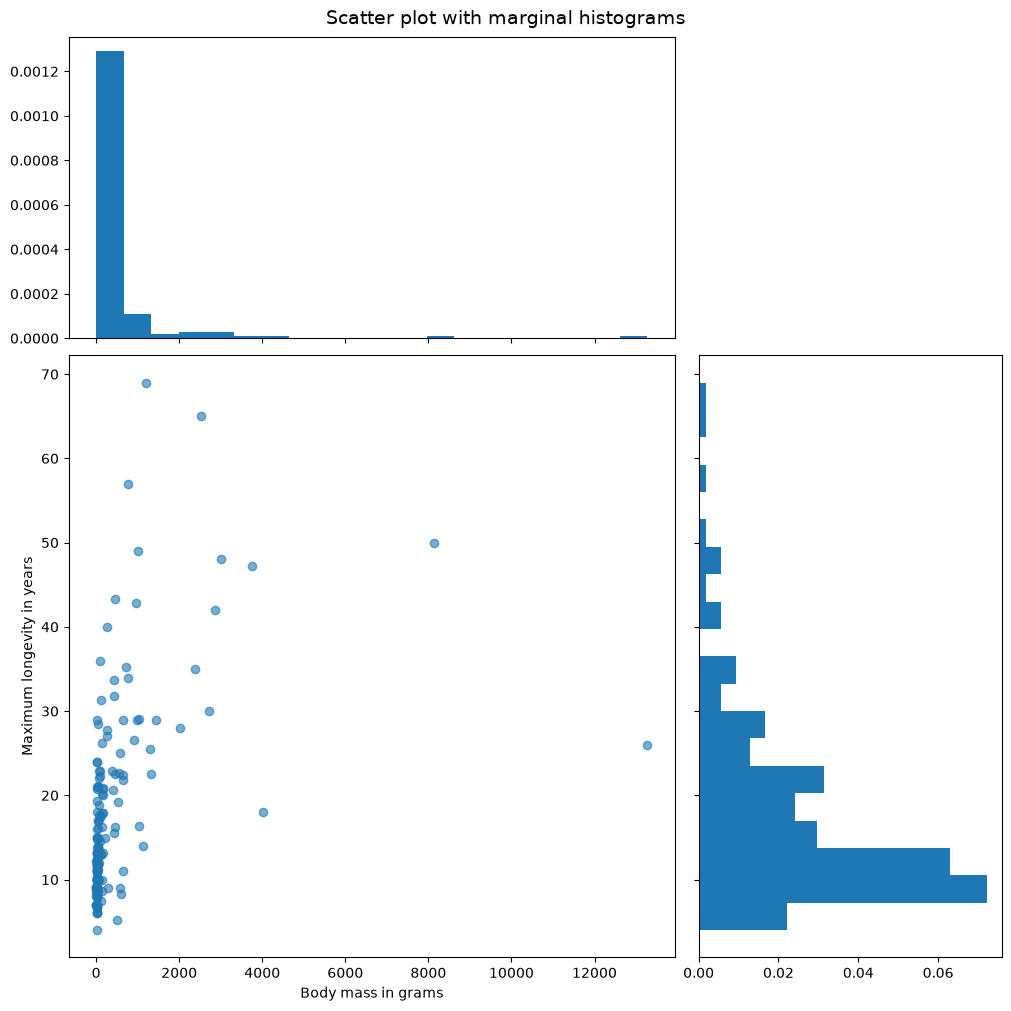

In [5]:
fig = plt.figure(figsize=(10, 10), dpi=100, constrained_layout=True)

gs = fig.add_gridspec(3, 3)

ax_main = fig.add_subplot(gs[1:3, 0:2])
ax_main.scatter(aves[mass], aves[longevity], alpha=0.6)
ax_main.set_xlabel('Body mass in grams')
ax_main.set_ylabel('Maximum longevity in years')

ax_top = fig.add_subplot(gs[0, 0:2], sharex=ax_main)
ax_top.hist(aves[mass], bins=20, density=True)
ax_top.tick_params(labelbottom=False)

ax_right = fig.add_subplot(gs[1:3, 2], sharey=ax_main)
ax_right.hist(aves[longevity], bins=20, density=True, orientation='horizontal')
ax_right.tick_params(labelleft=False)

fig.suptitle('Scatter plot with marginal histograms', fontsize=14)

plt.show()